# Breast Cancer Diagnosis with a Neural Network
Predicting whether a tumor is **malignant (M)** or **benign (B)** from cell-nucleus measurements (Breast Cancer Wisconsin dataset, 569 samples) using a Keras neural network. The results are compared with a Random Forest trained on the same data.

## 1. Import Libraries
Load pandas and numpy for data handling, matplotlib for plots, scikit-learn for preprocessing and evaluation, and Keras (TensorFlow) for the neural network.

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.layers import Dense , Dropout , Input 
from tensorflow.keras.models import Sequential
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score , classification_report , ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance
from sklearn.base import BaseEstimator , ClassifierMixin

## 2. Load the Dataset
Read `Cancer_Data.csv` into a DataFrame and preview the first 5 rows.

In [30]:
df = pd.read_csv("Cancer_Data.csv")
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


## 3. Drop Unnecessary Columns
Remove `id` (just an identifier) and `Unnamed: 32` (completely empty). Neither helps prediction.

In [31]:
df = df.drop(["id","Unnamed: 32"], axis=1)

## 4. Define Features (X) and Target (y)
- `X`: all measurement features
- `y`: the `diagnosis` column, encoded as numbers (B = 0, M = 1) because neural networks need numeric labels

In [32]:
x = df.drop("diagnosis", axis= 1)
y = df["diagnosis"]
y = y.map({"B": 0, "M": 1})

## 5. Train/Test Split
80% training, 20% testing, using the **same settings as the Random Forest notebook** (`test_size=0.2`, `random_state=42`, `stratify=y`). Both models are therefore tested on the same 114 samples.

In [33]:
x_trian , x_test , y_train , y_test = train_test_split( x, y, test_size=0.2, random_state=42, stratify=y)

## 7. Feature Scaling
Features have very different scales (e.g. `area_mean` is about 1000 while `smoothness_mean` is about 0.1), and neural networks are sensitive to this. `StandardScaler` is fitted on the training set only and then applied to the test set, which avoids data leakage.

In [34]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_trian)
x_test_scaled = scaler.transform(x_test)

## 8. Build the Neural Network
- Input layer with 30 features
- Dense (32, ReLU) → Dropout (0.3) → Dense (16, ReLU)
- Output: Dense (1, sigmoid), the probability of a tumor being malignant
- Optimizer: Adam, loss: binary cross-entropy

In [35]:
model_seq = Sequential([
    Input(shape=(30,)),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
])
model_seq.compile(
    optimizer = 'adam',
    loss = 'binary_crossentropy' ,
    metrics = ['accuracy']
)

## 9. Train the Model
Training uses 20% of the training data for validation, batch size 16, up to 100 epochs. `EarlyStopping` (patience 10) stops training when validation loss stops improving and restores the best weights.

In [36]:
history = model_seq.fit(
    x_train_scaled, y_train,
    validation_split = 0.2,
    epochs = 100,
    batch_size = 16,
    callbacks=[EarlyStopping(patience=10, restore_best_weights=True)],
    verbose = 0
)

## 11. Evaluation on the Test Set
Predictions are converted to classes with a 0.5 threshold. Accuracy plus the classification report (precision, recall, F1-score) are computed on the 114 test samples.

In [37]:
y_pred_nn = (model_seq.predict(x_test_scaled) > 0.5).astype(int).ravel()

print(accuracy_score(y_test, y_pred_nn))
print(classification_report(y_test, y_pred_nn))

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
0.9824561403508771
              precision    recall  f1-score   support

           0       0.97      1.00      0.99        72
           1       1.00      0.95      0.98        42

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



## 12. Confusion Matrix
Shows exactly where the model makes mistakes. The most important error here is a malignant tumor predicted as benign (false negative).

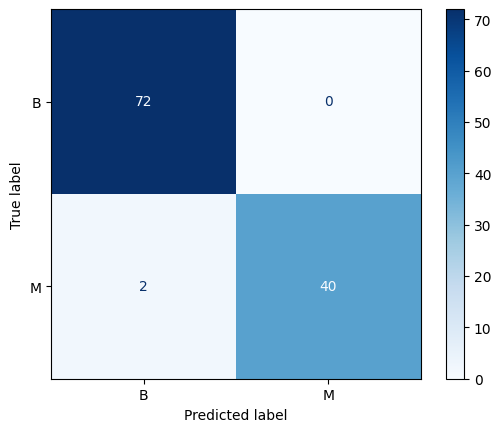

In [38]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_nn, display_labels=["B","M"], cmap="Blues")
plt.show()

## 13. Feature Importance (Permutation)
Neural networks have no built-in `feature_importances_`, so permutation importance is used: each feature is shuffled on the test set, and the drop in accuracy shows how much the model relies on it. A `KerasWrapper` class lets scikit-learn use the Keras model.

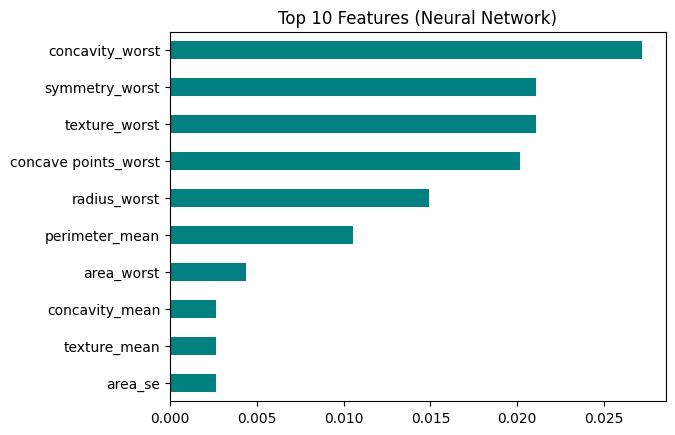

In [39]:
class KeraWrapper(ClassifierMixin, BaseEstimator):
    def __init__(self, model= None):
        self.model = model
    def fit(self , x , y):
        self.classes_ = np.array([0,1])
        return self
    def predict(self, x):
        return (self.model.predict(x, verbose =0) > 0.5).astype(int).ravel()

wrapped = KeraWrapper(model_seq)
wrapped.fit(x_test_scaled,y_test)

result = permutation_importance(
    wrapped, x_test_scaled, y_test,
    scoring='accuracy' , n_repeats=10 , random_state=42
)

imp_nn = pd.Series(result.importances_mean, index=x.columns)
imp_nn.sort_values().tail(10).plot(kind='barh', color= 'teal')
plt.title("Top 10 Features (Neural Network)")
plt.savefig("nn_feature_importance.png", dpi= 300 , bbox_inches= 'tight')
plt.show()

### Observations
- Top features for the neural network: `texture_worst`, `concave points_worst`, `concavity_worst`, `concave points_mean`, `smoothness_worst`.
- Random Forest (impurity-based) ranked `perimeter_worst`, `area_worst`, `concave points_worst` highest.
- Both models rely on the "worst" (largest-value) measurements, especially `concave points_worst`, which appears in both top lists.
- Importance values are small because many features are strongly correlated (e.g. radius, perimeter, area): shuffling one is partly compensated by the others.

## 14. Conclusion
- Test accuracy: ~98.2%
- Malignant recall: 0.95 (2 malignant cases missed out of 42)
- Malignant precision: 1.00 (no false alarms)
- Compared with Random Forest (accuracy 96.5%, malignant recall 0.90), the neural network missed fewer malignant cases on the same test split.
- Limitation: the comparison uses a single 114-sample test split, so the small difference may be due to chance. Cross-validation would give a more reliable comparison.